# Energy Explorer in Python — walkthrough

This notebook works through the `energy_explorer` package, a Python port of **ENERGY EXPLORER**. The original was a
Visual Basic 6 program for analysing measured building-energy data, written by Kelly Kissock and colleagues at the
Dept. of Mechanical Engineering, University of Dayton. The VB source is in `src/`.

The workflow follows the original program:

1. **Open data**: space-delimited numbers, with names in a `.var` sidecar file and `-99` as the no-data flag.
2. **Explore**: time series and XY plots.
3. **Group** records into *Pre* / *Post* retrofit periods.
4. **Fit a baseline model**: Mean, Median, 2P, MLR, 3PC/3PH, 4P, 5P (each change-point model with optional extra
   linear variables, "MVR"), and Bin Fit.
5. **Calculate savings** with ASHRAE-style uncertainty, plus an AR(1)-corrected variant for linear models.
6. Other tools: **time-scale change**, **Lean Energy Analysis**, and the **two-zone HVAC simulation**.

> **The data in `data/` is synthetic.** `scripts/make_sample_data.py` generates it with known, planted parameters, so
> you can check that the models recover them. The last section loads a real hourly file from 1995, `dhr.tmp`, which
> was found inside `src/EnergyExplorerSource.ZIP`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import energy_explorer as ee

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (10, 4)
ee.__version__

'0.1.0'

## 1. Open a data file
`read_data` loads `sample_daily.var` automatically when it finds it. Missing values (`-99`) become `NaN`.

In [2]:
ds = ee.read_data(DATA / "sample_daily.dat")
print(ds)
print("interval:", ds.interval.name, "| time fields:", ds.time_fields)
ds.data.head()

Dataset(name='sample_daily.dat', records=731, interval=daily, columns=['Site', 'Mo', 'Dy', 'Yr', 'DOW', 'CW', 'HW', 'WBE', 'Temp'])
interval: DAILY | time fields: {'mo': 'Mo', 'dy': 'Dy', 'yr': 'Yr'}


,Site,Mo,Dy,Yr,DOW,CW,HW,WBE,Temp
0,114.0,1.0,1.0,2019.0,3.0,30.17,38.20,42033.0,35.4
1,114.0,1.0,2.0,2019.0,4.0,31.65,49.79,42156.0,27.2
2,114.0,1.0,3.0,2019.0,5.0,29.44,39.11,40329.0,37.9
3,114.0,1.0,4.0,2019.0,6.0,30.83,36.03,41838.0,39.0
4,114.0,1.0,5.0,2019.0,7.0,30.47,52.53,28013.0,21.5


## 2. Explore: time series and XY

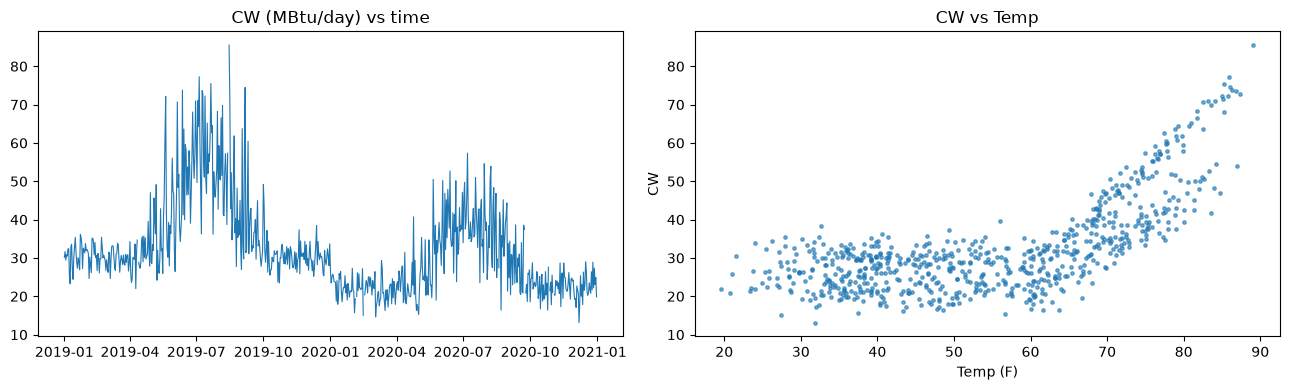

In [3]:
ts = ds.timestamps()
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ts, ds.data["CW"], lw=0.8); a.set_title("CW (MBtu/day) vs time")
b.scatter(ds.data["Temp"], ds.data["CW"], s=6, alpha=0.6); b.set_xlabel("Temp (F)"); b.set_ylabel("CW"); b.set_title("CW vs Temp")
plt.tight_layout()

## 3. Group into Pre / Post
Group 1 is the date range you give (inclusive). Every other record goes to group 2. To compute savings, name the groups `Pre` and `Post`.

In [4]:
ds = ee.group_by_date(ds, end="12/31/2019", names=("Pre", "Post"))
ds.summary()["group_counts"]

{'Pre': 365, 'Post': 366}

## 4. Fit the baseline models on the Pre period
All the model types are fitted to the same data so their statistics can be compared. Statistics follow the VB `Inf` routine: RMSE uses n − p degrees of freedom, and CV-RMSE = RMSE / ȳ.

In [5]:
specs = {"Mean": [], "Median": [], "2P": ["Temp"], "3PC": ["Temp"], "4P": ["Temp"], "5P": ["Temp"],
         "BinFit": ["Temp"], "MLR": ["Temp", "WBE"]}
fits = {k: ee.fit(ds, k, y="CW", x=x, group="Pre") for k, x in specs.items()}
pd.DataFrame({k: {"N": m.stats.n, "R2": m.stats.r2, "RMSE": m.stats.rmse, "CV-RMSE %": m.stats.cv_rmse,
                  "DW": m.stats.durbin_watson, "lag-1 autocorr": m.stats.autocorrelation}
              for k, m in fits.items()}).T

,N,R2,RMSE,CV-RMSE %,DW,lag-1 autocorr
Mean,363.0,NaN,12.300,33.005,NaN,NaN
Median,363.0,NaN,0.615,1.919,NaN,NaN
2P,360.0,0.612,7.684,20.601,1.060,0.469
3PC,360.0,0.943,2.944,7.892,1.757,0.120
4P,360.0,0.943,2.949,7.907,1.762,0.117
5P,360.0,0.942,2.967,7.955,1.765,0.116
BinFit,360.0,NaN,3.550,9.517,NaN,NaN
MLR,358.0,0.612,7.708,20.644,1.062,0.469


In [6]:
best = fits["3PC"]
print(best.summary())
best.params()

Type = 3PC  N = 360  R2 = 0.94  RMSE = 2.9437  CV-RMSE = 7.89%  DW = 1.76  AutoCorr = 0.12
Model: CW = 30.16  -  0.00 (62.30 - Temp)+  +  1.83 (Temp - 62.30)+


{'heating': False,
 'xcp': 62.30335999999999,
 'xcp_step': 0.013519999999999999,
 'ycp': 30.161673215201244,
 'se_ycp': 0.18071570566731873,
 'slope': 1.8298236215390276,
 'se_slope': 0.023754694640134435,
 'extra_coefs': [],
 'extra_se': []}

The synthetic Pre period was generated with **CW = 30 + 1.8·(Temp − 62)+ + noise**, so the 3PC fit should come back close to those values. Next, the change-point fits are plotted over the Pre data:

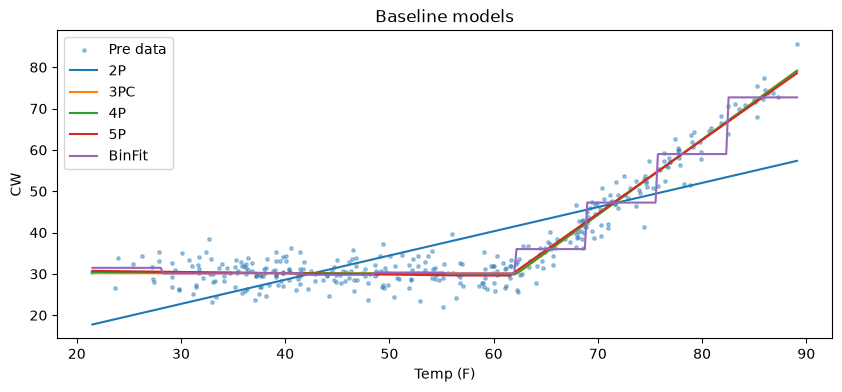

In [7]:
X, y, _ = ee.select_xy(ds, "CW", ["Temp"], "Pre")
grid = np.linspace(X.min(), X.max(), 300)
plt.scatter(X[:, 0], y, s=6, alpha=0.4, label="Pre data")
for k in ("2P", "3PC", "4P", "5P", "BinFit"):
    plt.plot(grid, fits[k].predict({"Temp": grid}), label=k)
plt.xlabel("Temp (F)"); plt.ylabel("CW"); plt.legend(); plt.title("Baseline models");

### Residuals
Every model's `.residuals` lines up with the dataset rows, the same way `SG_Resids` / `G1_Resids` did in the VB program.

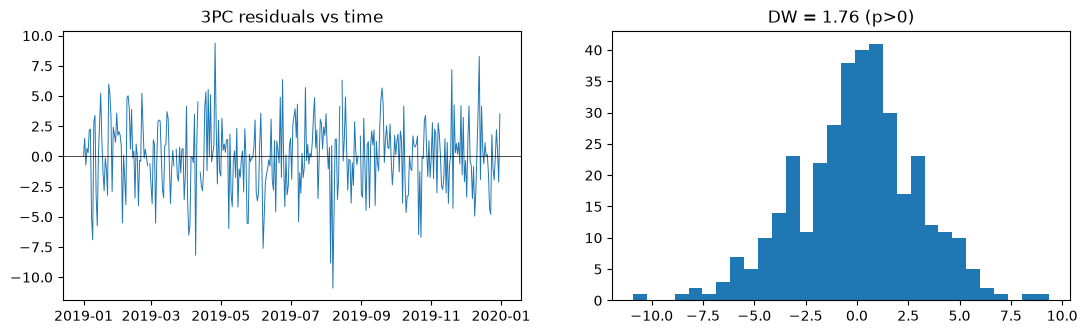

In [8]:
r = best.residuals
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.5))
a.plot(ts, r, lw=0.7); a.axhline(0, color="k", lw=0.5); a.set_title("3PC residuals vs time")
b.hist(r.dropna(), bins=30); b.set_title(f"DW = {best.stats.durbin_watson:.2f} ({best.stats.dw_test})");

## 5. Savings
Savings is the sum of the baseline prediction over the Post period minus the measured Post use. The uncertainty uses
`CalcSavingsCmd_Click`:

* baseline: 1.96 · RMSE · √(1 + 2/n_pre) · √n_post
* measurement: the measured total × the error percentage
* both combined in quadrature

In [9]:
sav = ee.calculate_savings(best, ds, measurement_error_pct=5)
print(sav.report())

 Observations During Post-retrofit Period: 355
 Adjusted Baseline Use During Post-retrofit Period = 13,182.9  ±109.0  ±0.8%
 Actual Use During Post-retrofit Period = 9,649.0  ±482.5  ±5.0%
 Total Savings During Post-retrofit Period = 3,533.9  ±494.6  ±14.0%
 Average Savings Per Observation During Post-retrofit Period = 10.0  ±1.4  ±14.0%


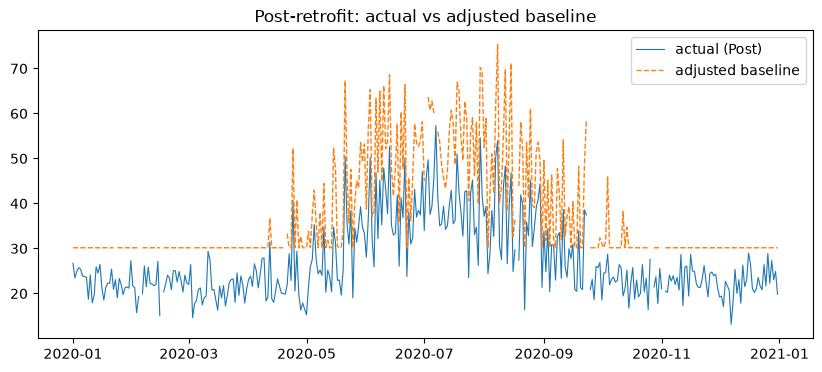

In [10]:
post = ds.group_mask(2)
plt.plot(ts[post], ds.data.loc[post, "CW"], lw=0.8, label="actual (Post)")
plt.plot(ts[post], sav.predicted[post], lw=1, ls="--", label="adjusted baseline")
plt.legend(); plt.title("Post-retrofit: actual vs adjusted baseline");

### Autocorrelation-corrected uncertainty (linear baselines)
`ProjectSavingsCmd_Click` has a fuller uncertainty calculation for Mean, 2P and MLR baselines. It accounts for
lag-1 (AR(1)) autocorrelation in the residuals and for the uncertainty in the regression coefficients. In the VB
code, ρ was effectively 0 for 2P and MLR because of a misspelled variable. The port estimates ρ by default; pass
`rho=0` to reproduce the original result.

In [11]:
from energy_explorer.savings import autocorrelated_savings_for_model
lin = fits["2P"]
pd.DataFrame({
    "simple (CalcSavings)": ee.calculate_savings(lin, ds).to_dict(),
    "AR(1), rho=0 (VB 2P behaviour)": autocorrelated_savings_for_model(lin, ds, rho=0).to_dict(),
    "AR(1), rho estimated": autocorrelated_savings_for_model(lin, ds).to_dict(),
}).loc[["savings", "savings_error", "rho"]]

,simple (CalcSavings),"AR(1), rho=0 (VB 2P behaviour)","AR(1), rho estimated"
savings,3509.925,3509.925,3509.925
savings_error,284.563,401.521,667.748
rho,NaN,0.000,0.468


## 6. Change the time scale
Totals are the default. Temperatures (and any other intensive variable) should be averaged. A monthly 3PC model is then fitted to the result.

In [12]:
monthly = ee.change_timescale(ds, "monthly", averages=["Temp", "DOW", "Site"])
monthly = ee.group_by_date(monthly, end="12/2019", names=("Pre", "Post"))
m_month = ee.fit(monthly, "3PC", y="CW", x="Temp", group="Pre")
print(m_month.summary())
monthly.data.head()

Type = 3PC  N = 12  R2 = 0.98  RMSE = 42.0816  CV-RMSE = 3.73%  DW = 3.22  AutoCorr = -0.65
Model: CW = 918.08  -  0.00 (61.24 - Temp)+  +  51.46 (Temp - 61.24)+


,Site,Mo,Yr,DOW,CW,HW,WBE,Temp
0,114.0,1.0,2019.0,4.000,949.59,1281.67,1.189e+06,33.790
1,114.0,2.0,2019.0,4.000,852.79,1067.79,1.061e+06,36.019
2,114.0,3.0,2019.0,4.065,920.89,939.66,1.115e+06,43.697
3,114.0,4.0,2019.0,3.900,900.16,609.28,1.157e+06,53.563
4,114.0,5.0,2019.0,4.097,1195.26,466.60,1.196e+06,65.958


## 7. Lean Energy Analysis
A 3PH model with an extra production variable (3PH-MVR) splits gas use into three parts: facility (independent of weather and production), weather-dependent, and production-dependent.

In [13]:
lea_ds = ee.read_data(DATA / "sample_monthly_lea.dat")
lea_model = ee.fit(lea_ds, "3PH", y="NatGas", x=["Toa", "Prod"])
print(lea_model.summary())
lea = ee.lean_energy_analysis(lea_model, lea_ds)
pd.Series(lea.to_dict()["totals"]).to_frame("total").assign(share_pct=pd.Series(lea.shares()))

Type = 3PH  N = 24  R2 = 0.99  RMSE = 9.6478  CV-RMSE = 3.69%  DW = 2.14  AutoCorr = -0.08
Model: NatGas = 72.46  -  -8.72 (62.50 - Toa)+  +  0.00 (Toa - 62.50)+  +  0.01773 Prod

,total,share_pct
facility,1739.122,27.737
weather,2742.940,43.746
production,1788.038,28.517
total,6270.100,NaN


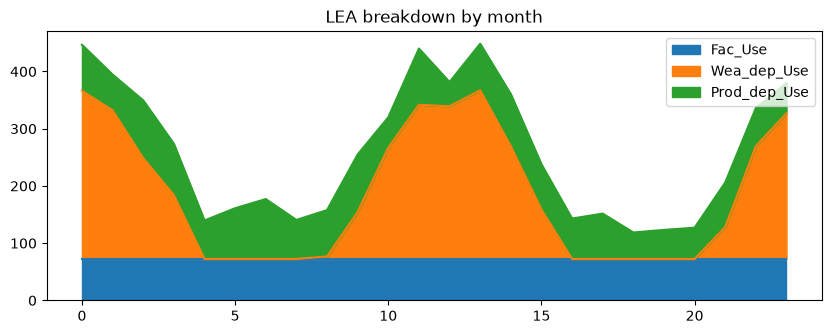

In [14]:
lea.components[["Fac_Use", "Wea_dep_Use", "Prod_dep_Use"]].plot.area(figsize=(10, 3.5), title="LEA breakdown by month");

## 8. Two-zone HVAC simulation
This is a port of Kissock's ESIM model. It simulates a VAV system with an economizer and latent loads, using one year of hourly weather and electricity data.

In [15]:
hourly = ee.read_data(DATA / "sample_hourly.dat")
params = ee.SystemParams(system="vav", economizer=True, latent=True, n_occupants=800)
sim = ee.simulate(hourly, params, wbe="WBE", toa="Toa", woa="Woa")
print("infeasible hours:", int(sim.infeasible.sum()))
sim.describe().T[["mean", "min", "max"]]

infeasible hours: 0


,mean,min,max
CC,3.005,0.204,17.499
HC,0.134,0.000,0.819
EDE,58.777,-60.103,100.000


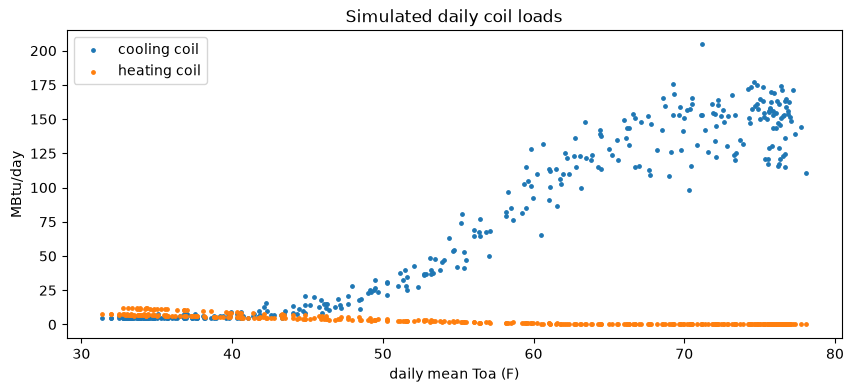

In [16]:
from energy_explorer.simulation import add_simulation
h2 = add_simulation(hourly, params, wbe="WBE", toa="Toa", woa="Woa")
d2 = ee.change_timescale(h2, "daily", averages=["Toa", "Woa", "EDE1_(%)"])
plt.scatter(d2.data["Toa"], d2.data["CC1_(MBtu/hr)"], s=6, label="cooling coil")
plt.scatter(d2.data["Toa"], d2.data["HC1_(MBtu/hr)"], s=6, label="heating coil")
plt.xlabel("daily mean Toa (F)"); plt.ylabel("MBtu/day"); plt.legend(); plt.title("Simulated daily coil loads");

## 9. A real legacy data file
`src/EnergyExplorerSource.ZIP` contains `dhr.tmp`, a scratch file that the VB program wrote when it converted hourly data to daily. It parses with no changes. Only the four time columns are known, so the other columns keep default names.

In [17]:
import zipfile
zpath = ROOT / "src" / "EnergyExplorerSource.ZIP"
if zpath.exists():
    with zipfile.ZipFile(zpath) as z:
        text = z.read("dhr.tmp").decode("latin-1")
    n_cols = len(text.split("\n", 1)[0].split())
    names = ["Mo", "Dy", "Yr", "Hr"] + [f"V{i:02d}" for i in range(5, n_cols + 1)]
    legacy = ee.read_data_text(text, names, name="dhr.tmp")
    print(legacy)
    legacy_daily = ee.change_timescale(legacy, "daily", averages=[c for c in legacy.value_columns])
    display(legacy_daily.data.head())
else:
    print("EnergyExplorerSource.ZIP not found; skipping")

Dataset(name='dhr.tmp', records=8760, interval=hourly, columns=['Mo', 'Dy', 'Yr', 'Hr', 'V05', 'V06', 'V07', 'V08', 'V09', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17'])


,Mo,Dy,Yr,V05,V06,V07,V08,V09,V10,V11,V12,V13,V14,V15,V16,V17
0,1.0,1.0,1995.0,21.071,-30.125,55.021,2.300,0.0,57.321,0.0,0.0,0.0,0.638,NaN,NaN,NaN
1,1.0,2.0,1995.0,17.496,-34.125,61.317,2.300,0.0,63.646,0.0,0.0,0.0,0.638,NaN,NaN,NaN
2,1.0,3.0,1995.0,25.462,-29.458,52.346,2.325,0.0,54.675,0.0,0.0,0.0,0.638,NaN,NaN,NaN
3,1.0,4.0,1995.0,18.283,-31.708,58.096,2.400,0.0,60.450,0.0,0.0,0.0,0.638,NaN,NaN,NaN
4,1.0,5.0,1995.0,3.096,-43.083,78.367,2.400,0.0,80.742,0.0,0.0,0.0,0.638,NaN,NaN,NaN


## 10. Serialising a model (how the API uses it)
A fitted model converts to a plain JSON dict and back again. The FastAPI service (`api/`) relies on this to store
baselines and reuse them later for savings.

In [18]:
import json
d = best.to_dict()
print(json.dumps({k: d[k] for k in ("kind", "model_type", "xcp", "ycp", "slope", "equation")}, indent=2))
restored = ee.model_from_dict(json.loads(json.dumps(d)))
np.allclose(restored.predict(ds.data), best.predict(ds.data), equal_nan=True)

{
  "kind": "3p",
  "model_type": "3PC",
  "xcp": 62.30335999999999,
  "ycp": 30.161673215201244,
  "slope": 1.8298236215390276,
  "equation": "CW = 30.16  -  0.00 (62.30 - Temp)+  +  1.83 (Temp - 62.30)+"
}


True